# *Free My TV vs Google TV: does a custom home screen run better?*

#### This project follows a TCL Google TV (Android 12, 2 GB of RAM) from its factory home screen to a custom, ad-free one with an animated, illustrated sky. At every step the same question came back: **did the TV get faster or slower?** The notebook answers it with data collected from the TV itself, keeps only the differences that are bigger than the measurement noise, and says clearly which ones are still uncertain.

#### The project, step by step

| Version | Step of the project | What changed on the TV |
|---|---|---|
| **V0** | Starting point | Google's factory home screen, every pre-installed extra on, normal animations |
| **V1** | Cleanup | 20 unused extras turned off (never uninstalled) and animations at 0.5x |
| **V2** | New home screen | [Free My TV](https://github.com/simbasjungles/free-my-tv), an open-source, ad-free home screen, as published |
| V3, V4 | Building the fork | picks, a title shelf, then the animated sky and weather (measured only during development, section 8) |
| **V5** | The fork | this repository's version: sky, weather, a lookout tower and music scenes |
| **V6** | Optimization | the same scenes with the sky painted at half resolution in its own layer |

#### Where the data comes from

There is no downloaded dataset here: every number was **collected from the TV** with the scripts in `collector/`, over adb (Android's debugging bridge, read-only except for the benchmark's restart).

* `benchmark.py` puts each version through **the same test**: restart the TV, rest 3 minutes on the home screen, then measure memory, how fast the home screen comes back from another app, 2 minutes moving around it with the arrows (the time of every frame), and opening Netflix, Nuvio and Spotify.
* `pull_tv_log.py` brings home the log the home screen keeps on the TV by itself (one line every 15 minutes while the TV is on).
* `build_datasets.py` turns the raw files (kept in `datasets/private/`, never published) into the anonymized files in `datasets/`: no IP address and no dates (a date becomes *day N*).

Because we collected the data ourselves, there is little to clean. Section 2 still checks it, so a reviewer can see why it can be trusted.

## *1. Import and Overview*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
D = "../datasets/"
IMG = "../images/"
ORDER = ["V0", "V1", "V2", "V5", "V6"]
COLOR = {"V0": "#9AA0A6", "V1": "#5F6368", "V2": "#72B7B2", "V5": "#F58518", "V6": "#B279A2"}

bench = pd.read_csv(D + "benchmark.csv")                 # one row per test run
frames = pd.read_csv(D + "benchmark_frames.csv")         # frame-time histogram of each run (home screen)
apps = pd.read_csv(D + "benchmark_apps.csv")             # one row per app opened in each run
changes = pd.read_csv(D + "changes.csv")                 # what the cleanup (V1) turned off
perf = pd.read_csv(D + "performance.csv")                # measurements taken during development (V3, V4)
log = pd.read_csv(D + "tv_perf.csv")                     # the TV's own log, every 15 minutes

for name, df in [("bench", bench), ("frames", frames), ("apps", apps), ("changes", changes), ("perf", perf), ("log", log)]:
    print(f"{name:8} {df.shape[0]:4} rows x {df.shape[1]:2} columns")

bench       6 rows x 13 columns
frames    225 rows x  5 columns
apps       18 rows x 13 columns
changes    34 rows x  5 columns
perf       15 rows x  6 columns
log        81 rows x 13 columns


In [2]:
bench.drop(columns="label")

,version,boot_s,home_s,mem_available_mb,home_mb,open_ms,frames,janky_pct,frame_p50_ms,frame_p90_ms,frame_p99_ms,run
0,V5,36,36,863,169,104,3887,9.08,19,31,36,1
1,V2,49,49,912,91,114,1200,4.58,14,32,53,1
2,V0,37,37,854,200,138,1347,2.38,14,19,34,1
3,V1,35,36,803,168,148,917,1.74,17,21,32,1
4,V5,34,34,877,152,97,3584,11.52,20,30,34,2
5,V6,35,35,916,145,105,3000,2.20,14,21,31,1


#### What does the first look tell us?

* `bench` has **6 runs**: one per version, and two for V5. Each column is one measurement of the test: `boot_s` (restart to home screen, seconds), `mem_available_mb` (RAM free for apps), `home_mb` (the home screen's own RAM), `open_ms` (time for the home screen to come back from another app), and the frame summary of the 2 minutes moving with the arrows.
* `frames` keeps every frame of those 2 minutes as a histogram: `frame_ms` is how long a frame took and `frames` how many took that long. A frame of 16.7 ms or less means **60 frames per second (fps)**, the TV's maximum.
* `changes` lists every package turned off along the project, by round: the two cleanup rounds, the switch of home screen (Google's own home screen pieces) and the music round. Nothing was uninstalled, so everything can be turned back on.

In [3]:
changes[changes["round"] != "factory"].groupby("round")["package"].count().rename("packages turned off")

round
home screen     6
music           2
round 1        18
round 2         7
Name: packages turned off, dtype: int64

## *2. Data Quality Check*

#### Is there anything to clean?

We don't expect much, since the scripts write the files themselves, but four things are worth checking: missing values, duplicates, the data types, and that nothing personal reached the public files.

In [4]:
for name, df in [("bench", bench), ("frames", frames), ("apps", apps), ("log", log)]:
    print(f"{name:7} missing values: {df.isna().sum().sum():4}   duplicated rows: {df.duplicated().sum()}")

bench   missing values:    0   duplicated rows: 0
frames  missing values:    0   duplicated rows: 0
apps    missing values:   30   duplicated rows: 0
log     missing values:  106   duplicated rows: 0


In [5]:
apps[apps["frames"].isna()][["version", "app", "launch_ms", "frames"]]

,version,app,launch_ms,frames
0,V5,Netflix,913,NaN
3,V2,Netflix,818,NaN
6,V0,Netflix,948,NaN
9,V1,Netflix,705,NaN
12,V5,Netflix,1001,NaN
15,V6,Netflix,874,NaN


In [6]:
missing = log.isna().sum()
missing[missing > 0].rename("missing").to_frame().assign(lines_without_frames=(log["frames"] == 0).sum())

,missing,lines_without_frames
app_on_screen,44,50
histogram,50,50
graphics_mb,4,50
cpu_pct,4,50
thermal,4,50


In [7]:
log[["graphics_mb", "cpu_pct", "thermal"]].isna().groupby(log["day"]).sum()

,graphics_mb,cpu_pct,thermal
day,,,
4,4,4,4
5,0,0,0
6,0,0,0
7,0,0,0


#### Where are the missing values from, and do they need fixing?

They are all expected, so **nothing is filled in or removed**:

* **Netflix has no frame data** in `apps`: Netflix protects its screens, and Android doesn't report its frames. Its launch time and memory are still there.
* **The TV's log, `app_on_screen` and `histogram`:** 19 lines where the home screen drew no frame at all (`frames` = 0), because the screen was off or another app was open. With no frames there's no histogram; section 9 only uses lines with frames.
* **The TV's log, GPU memory, CPU and temperature:** missing in the 4 lines of day 4, because those columns were added to the log on day 5. Earlier lines simply didn't measure them.

No row is duplicated. Next, the types and the privacy check.

In [8]:
bench.dtypes.value_counts()

int64      10
str         2
float64     1
Name: count, dtype: int64

In [9]:
public = pd.concat([pd.read_csv(D + f) for f in ["benchmark.csv", "benchmark_apps.csv", "tv_perf.csv", "changes.csv"]])
text = public.fillna("").astype(str).apply(" ".join, axis=1)
print("IP addresses:", text.str.contains(r"\b\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}\b").sum())
print("Dates:", text.str.contains(r"\d{4}-\d{2}-\d{2}").sum())

IP addresses: 0
Dates: 0


#### Conclusion of the check

Every measurement is already a number, there are no duplicates, the missing values are explained by how Android works, and the public files hold no IP address and no dates. The data is ready as it is.

## *3. How do we know a difference is real?*

#### The problem

Each version was tested **once** (V5 twice). With one run, part of any difference is just chance: the TV may be checking for updates, warming up, and so on. So before comparing versions we need to know **how much the same version changes from one run to the next**. V5's two runs show exactly that.

In [10]:
v5 = bench[bench["version"] == "V5"].set_index("run")
cols = ["boot_s", "mem_available_mb", "home_mb", "open_ms"]
noise = pd.DataFrame({"run 1": v5.loc[1, cols], "run 2": v5.loc[2, cols]})
noise["difference %"] = (100 * (noise["run 1"] - noise["run 2"]).abs() / noise[["run 1", "run 2"]].mean(axis=1)).round(1)
noise

,run 1,run 2,difference %
boot_s,36,34,5.7
mem_available_mb,863,877,1.6
home_mb,169,152,10.6
open_ms,104,97,7.0


In [11]:
def fps(ms):
    """Frame time (ms) as frames per second; the TV can't go above 60."""
    return 1000 / np.maximum(ms, 1000 / 60)


def avg_fps(df):
    return np.average(fps(df["frame_ms"]), weights=df["frames"])


frames.groupby(["version", "run"]).apply(avg_fps, include_groups=False).round(1).rename("average fps").to_frame().T

version        V0    V1    V2    V5          V6
run             1     1     1     1     2     1
average fps  58.0  55.0  52.4  49.1  49.7  57.2

#### The rule used from here on

* The same version changed **up to 11%** between runs in time and memory, so a gap counts as **relevant only above 15%** of the factory value (V0). Anything smaller is reported as *no difference*.
* The average fps is much steadier, because it's measured over thousands of frames: V5's two runs differ by **0.6 fps**. A gap counts as **relevant above 2 fps** (more than three times that).
* A gap above the threshold that has **no explanation and only one run** behind it is marked **uncertain**: it needs a repeat before anyone draws conclusions from it.

In [12]:
mean = bench.groupby("version").mean(numeric_only=True).reindex(ORDER)
LIMIT = 0.15


def verdict(col):
    base = mean.loc["V0", col]
    gap = 100 * (mean[col] - base) / base
    return gap.round(0).astype(int).astype(str) + "%" + np.where(gap.abs() > 100 * LIMIT, "  relevant", "")


pd.DataFrame({c: verdict(c) for c in cols}).T.drop(columns="V0")

version,V1,V2,V5,V6
boot_s,-5%,32% relevant,-5%,-5%
mem_available_mb,-6%,7%,2%,7%
home_mb,-16% relevant,-54% relevant,-20% relevant,-28% relevant
open_ms,7%,-17% relevant,-27% relevant,-24% relevant


#### What the table says

Gaps against the factory home screen (V0), per version:

* **Back to the home screen (`open_ms`)** and **the home screen's own RAM (`home_mb`)** have relevant gaps: sections 4 and 5.
* **RAM free for apps (`mem_available_mb`)** never moves more than 7%: *no difference*.
* **Restart time (`boot_s`)** is the same in four versions, but V2 took 32% longer. Nothing in the original Free My TV explains a slower restart, and there was only one run: **uncertain**, and left out of the conclusions (section 7).

## *4. Back to the home screen*

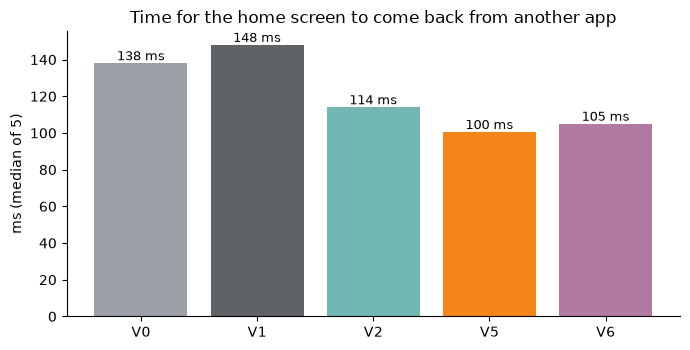

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(ORDER, mean["open_ms"], color=[COLOR[v] for v in ORDER])
for x, v in enumerate(mean["open_ms"]):
    ax.text(x, v, f"{v:.0f} ms", ha="center", va="bottom", fontsize=9)
ax.set(title="Time for the home screen to come back from another app", ylabel="ms (median of 5)")
plt.tight_layout()
plt.show()

#### Is the new home screen faster to come back to?

**Yes, and it's the clearest gain of the project.** Google's home screen takes 138 to 148 ms; every Free My TV version, 100 to 114 ms: **about 25% faster**, well above the 15% threshold. The cleanup (V1) didn't help here, it's the home screen itself that's lighter.

Through the remote's Home button, which goes through more of Android, the gap was even bigger: Free My TV's own settings measured **738 ms on Google's home screen against 96 ms**. That was a single measurement outside the test, so it's mentioned here but not used in the charts.

## *5. The home screen's own memory*

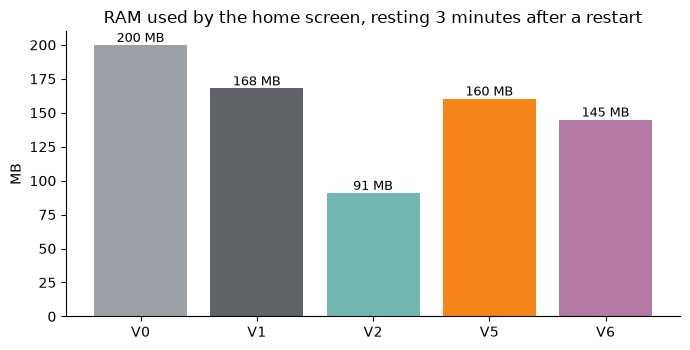

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(ORDER, mean["home_mb"], color=[COLOR[v] for v in ORDER])
for x, v in enumerate(mean["home_mb"]):
    ax.text(x, v, f"{v:.0f} MB", ha="center", va="bottom", fontsize=9)
ax.set(title="RAM used by the home screen, resting 3 minutes after a restart", ylabel="MB")
plt.tight_layout()
plt.show()

#### Does the animated sky cost memory?

* Google's home screen uses **200 MB**; the original Free My TV **91 MB**, less than half.
* This fork, with the sky, the weather and the tower, uses about **160 MB** (V5) and **145 MB** after the optimization (V6): the illustrated sky costs about 55 MB over the original, but the home screen still uses **28% less than Google's** (relevant).
* The cleanup (V1, 168 MB) is 16% below V0, just over the threshold, but turning off extras that weren't running shouldn't change the home screen's own memory, and RAM free for apps didn't move: we treat it as **uncertain**.

## *6. Smoothness: frames per second*

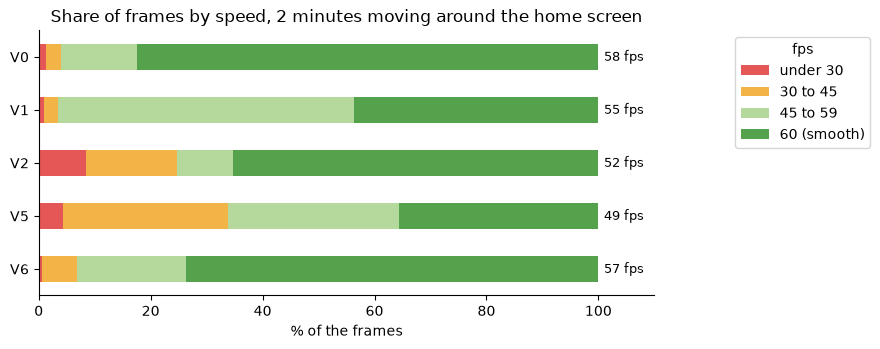

In [15]:
band = pd.cut(fps(frames["frame_ms"]), [0, 30, 45, 59, 61], labels=["under 30", "30 to 45", "45 to 59", "60 (smooth)"])
share = frames.assign(band=band).groupby(["version", "band"], observed=False)["frames"].sum().unstack()
share = (100 * share.div(share.sum(axis=1), axis=0)).reindex(ORDER)
avg = frames.groupby("version").apply(avg_fps, include_groups=False).reindex(ORDER)

ax = share.plot.barh(stacked=True, color=["#E45756", "#F2B447", "#B5D99C", "#54A24B"], figsize=(9, 3.6))
for y, v in enumerate(ORDER):
    ax.text(101, y, f"{avg[v]:.0f} fps", va="center", fontsize=9)
ax.set(title="Share of frames by speed, 2 minutes moving around the home screen", xlabel="% of the frames", ylabel="", xlim=(0, 110))
ax.invert_yaxis()
ax.legend(title="fps", bbox_to_anchor=(1.12, 1), loc="upper left")
plt.tight_layout()
plt.savefig(IMG + "fps-by-version.png", dpi=110, bbox_inches="tight")
plt.show()

In [16]:
rng = np.random.default_rng(0)
rows = []
for v in ORDER:
    g = frames[frames["version"] == v]
    each = np.repeat(fps(g["frame_ms"]).to_numpy(), g["frames"].to_numpy())   # one value per frame
    boot = [rng.choice(each, each.size).mean() for _ in range(500)]
    rows.append((v, each.mean(), *np.percentile(boot, [2.5, 97.5])))
ci = pd.DataFrame(rows, columns=["version", "average fps", "low (95%)", "high (95%)"]).set_index("version").round(1)
ci["vs V0"] = (ci["average fps"] - ci.loc["V0", "average fps"]).round(1)
ci

,average fps,low (95%),high (95%),vs V0
version,,,,
V0,58.0,57.7,58.3,0.0
V1,55.0,54.6,55.4,-3.0
V2,52.4,51.7,53.1,-5.6
V5,49.4,49.2,49.6,-8.6
V6,57.2,57.0,57.5,-0.8


#### Did the animated sky make the home screen stutter, and was it fixed?

The interval in the table is a *bootstrap*: the frames are drawn again at random 500 times to see how much the average could move. The intervals are narrow (thousands of frames per run), but frames that follow each other aren't independent, so the 2 fps rule from section 3 is still the one that decides.

* **V5 paid for its sky:** 49 fps on average, only 40% of the frames at 60 fps. Measured frame by frame, the TV's graphics chip (an Amlogic T5M) was repainting the whole sky on every frame of the shelf moving.
* **V6 fixed it: 57 fps, +8 fps over V5** (relevant). The sky got its own layer, painted at half resolution, and the shelf now moves over it without repainting it.
* **V6 against the factory home screen: -0.8 fps**, below the 2 fps rule: **no difference**. The fork keeps every scene and is as smooth as Google's home screen.
* V1 (-3 fps) and V2 (-6 fps) are below V0. V2, the original Free My TV, is lighter in memory but has big photos that move with the titles; for V1 there's no clear reason, and it's one run: **uncertain**.

## *7. What did not change*

In [17]:
a = apps.groupby(["app", "version"])[["launch_ms", "mem_available_mb"]].mean().unstack()["launch_ms"][ORDER].round(0)
a

version,V0,V1,V2,V5,V6
app,,,,,
Netflix,948.0,705.0,818.0,957.0,874.0
Nuvio,1075.0,1401.0,1386.0,1464.0,1370.0
Spotify,1196.0,1218.0,1148.0,1180.0,1183.0


#### Which results are left out of the conclusions, and why?

* **Opening the apps.** Netflix takes 0.7 to 1.0 s, Spotify 1.1 to 1.2 s and Nuvio 1.1 to 1.6 s in every version. Cold app launches vary a lot run to run (V5's Nuvio changed 14% between its two runs), and no version is consistently faster or slower: **no difference**. The home screen behind the apps doesn't slow them down.
* **RAM free with an app open.** It's lower with the fork (its home screen stays in memory behind the app, with the sky ready to come back), but V5's two runs differ by up to 28% here: **uncertain**. Android still had room: nothing was closed for lack of memory.
* **Restart time.** 34 to 37 s in four versions; V2's 49 s comes from a single run with no explanation: **uncertain**.
* **RAM free for apps at rest.** Within 7% in every version: **no difference**. The extras turned off in V1 weren't running anyway.

## *8. How the animated sky got light: the rain*

#### Was the rain animation too heavy for the TV?

The versions in between (V3, V4) were measured during development, while switching titles in the rain, the heaviest moment for the graphics chip. These are single measurements, but the gaps are huge (from 39% of the frames late to none), far beyond any noise.

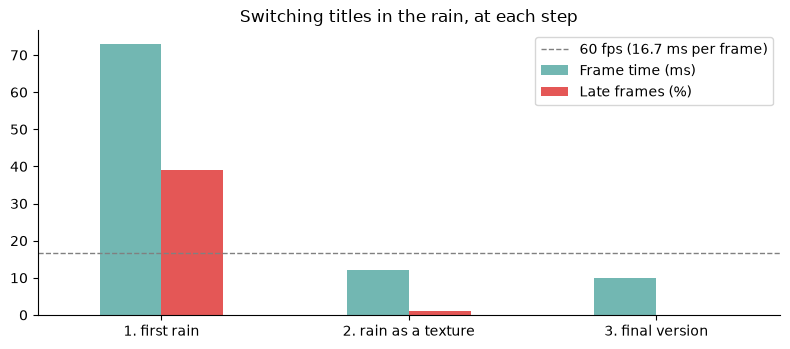

In [18]:
fr = perf[perf["metric"].isin(["janky_pct", "frame_ms"])].pivot_table(index="stage", columns="metric", values="value", sort=False)
fr = fr[["frame_ms", "janky_pct"]].rename(columns={"frame_ms": "Frame time (ms)", "janky_pct": "Late frames (%)"})
fr.index = ["1. first rain", "2. rain as a texture", "3. final version"]
ax = fr.plot.bar(rot=0, color=["#72B7B2", "#E45756"], figsize=(8, 3.6))
ax.axhline(16.7, ls="--", c="gray", lw=1, label="60 fps (16.7 ms per frame)")
ax.set(title="Switching titles in the rain, at each step", xlabel="")
ax.legend()
plt.tight_layout()
plt.savefig(IMG + "frame-times.png", dpi=110, bbox_inches="tight")
plt.show()

1. **First rain:** three layers of drops drawn one by one, every frame, with the sky behind them redrawn too: **39% of the frames late**, about 73 ms each (under 14 fps).
2. **Rain as a texture:** the drops became a ready-made picture that just slides, and the sky stands still while the titles move: **1% late**, about 12 ms.
3. **Final version**, with the tower and the music scenes: **no late frames**, about 10 ms.

The same idea, draw less and reuse more, is what turned V5 into V6 in section 6.

## *9. Through the day (in progress)*

#### Is the home screen as smooth at night as by day?

The sky changes with the time of day (sunrise, morning, midday, sunset, night, deep night), and some scenes have more moving parts than others. The home screen writes its own log on the TV, one line every 15 minutes while the TV is on, so this can be answered from normal use instead of a test.

In [19]:
use = log[(log["frames"] > 0)]
rows = [(r.day, r.period, int(ms), int(n)) for r in use.itertuples() for ms, n in (p.split(":") for p in str(r.histogram).split())]
h = pd.DataFrame(rows, columns=["day", "period", "frame_ms", "frames"])
summary = h.groupby("period").apply(lambda g: pd.Series({"days": g["day"].nunique(), "frames": g["frames"].sum(), "average fps": round(avg_fps(g), 1)}), include_groups=False)
summary

,days,frames,average fps
period,,,
midday,3.0,27873.0,56.5
morning,1.0,24008.0,56.5
night,2.0,19899.0,57.1
sunset,3.0,123836.0,56.4


#### Not enough data yet

The table shows how many days each period has so far: only a few, from the first week of use, with some periods missing. A few evenings can't tell a scene apart from what was on screen that day, so **this section is not a result yet**: it needs **2 to 4 weeks** of normal use. The TV keeps logging on its own; `collector/pull_tv_log.py` brings the new lines home and the notebook and the dashboard update by themselves.

## *10. Conclusions*

#### What the data supports

* **Coming back to the home screen is about 25% faster** with Free My TV (100 to 114 ms against 138 to 148 ms).
* **The home screen uses 28% less memory than Google's** (145 MB against 200 MB), even with the animated sky.
* **After the optimization (V6) it's as smooth as the factory home screen:** 57 against 58 fps, a gap smaller than the noise, up from 49 fps in V5.
* **Making the rain a sliding texture** took the heaviest moment from 39% of the frames late to none.

#### What it doesn't support (yet)

* The cleanup alone (V1) changed nothing measurable that we can trust; its gain is less clutter, not speed.
* App launch times, RAM with an app open and restart times don't show consistent differences.
* The effect of each time of day needs a few more weeks of the TV's own log.

#### What was given up

With Free My TV, Google's home screen is off, and it's what answers the voice assistant's film and series requests ("show me comedies"): those come back weaker. Opening apps, playing music, the weather and questions still work.